Here we provide a minimal working example for generating attention maps for FFPE slides of TCGA-BRCA images.

In [1]:
import pickle
import numpy as np
import os
from sklearn.linear_model import LogisticRegression as LR
from sklearn import metrics
import scipy as sp
from scipy.stats import norm
import matplotlib.pyplot as plt
import SAMPLER as SAMPLER

First we set hyperparameters used in the code:

Nres is the reslution used to store the log likelihhod ratio (LLR) of the kernel density estimates of each SAMPLER feature between two classes. The figures in the mansucript use Nres=100, but here we set Nres=20 to reduce computation cost.

PT is the p-value threshold used to filter SAMPLER features. Only SAMPLER features with p-values < PT are fed to the logistic regression classifer.

bws is the bandwidth of the kernel density estimator used to compute the LLR over a predetermined set of values.

REPS is the regularization value used for computing the LLR

SAMPLERrate is the number of percentiles SAMPLER uses to encode slide level features, throughout we have used 10 deciles, 5th,15th,...,95th percentiles.

fdim is the number of features used to encode each tile, given we use InceptionV3 each tile is encoded in a 2048-dimensional feature space.

sdim is the feature dimensionality of the slide-level representation.

numclasses is the number of classes in the classification task. Here it is set to 2, and the minimal code provided here only handles binary classification problems.

dsr is the down sampling ratio used for generating attention maps. Therefore, attention maps are effectively rendered at 20X/dsr

In [3]:
Nres=20
PT=0.001
bws=0.1
REPS=1
dsr=4
fdim=2048
pers=[5,15,25,35,45,55,65,75,85,95]
SAMPLERrate=len(pers)
sdim=fdim*SAMPLERrate
numclasses=2

Now we load the provided pickle file containing the necessary variables for our example. In order to generate example classifiers and attention maps we have made a train/test split using sklearn's train_test_split function. The following are stored in the pickle file:

Ptrain: list of patient IDs used for training

Ytrain: label of those patients, 0 for IDC and 1 for ILC

Ptest: list of patient IDs used for testing

Ytest: label of those patients, 0 for IDC and 1 for ILC

patD: a dictionary containing patient info. Each key is patient ID. Each entry is the pateint's label and the slides corresponding to the patient

Xtrain: SAMPLER features of WSIs of patients in the train set.

Ytrain: label of train slides.

Xtest: SAMPLER features of WSIs of patients in the test set.

Ytest: label of test slides.

Note: Xtrain and Xtest have 3 * 10 * 2048 columns. The first 10 * 2048 columns are the SAMPLER features of the small tile, the second 20480 features are the SAMPLER features of medium tiles, and the final 20480 features are the SAMPLER features of the large tiles.

In [4]:
W=pickle.load(open('TCGA_BRCA_DX20X.p','rb'))
Ptrain=W['Ptrain']
Ytrain=W['Ytrain']
Ptest=W['Ptest']
Ytest=W['Ytest']
Xtrain=W['Xtrain']
Ytrain=W['Ytrain']
Xtest=W['Xtest']
Ytest=W['Ytest']

Here we train the logistic regression classifiers using SAMPLER features and compute their AUCs. We first need to compute some p-values!

In [5]:
(T,P)=sp.stats.ttest_ind(Xtrain[Ytrain==0,:],Xtrain[Ytrain==1,:])

While we have the p-values, le'ts put them in a different shape and compute their logs. They will be useful for computing attention maps later on.

In [6]:
Pmat=np.zeros((SAMPLERrate,3*fdim))
for i in range(SAMPLERrate):
    Pmat[i,:fdim]=P[i*fdim:(i+1)*fdim]
    Pmat[i,fdim:2*fdim]=P[fdim+i*fdim:fdim+(i+1)*fdim]
    Pmat[i,2*fdim:3*fdim]=P[2*fdim+i*fdim:2*fdim+(i+1)*fdim]

Wmat=-1*np.log(Pmat)

Now lets train the logisctic regression classifiers. We use the following simple trick. In order to train a LR model using small tiles, we replace the p-values of the medium and large tiles with 1. Thereby they are larger than PT are not used. Similarly other models are implemented. We use liblinear solver, max_iter=1000, and C=100 in this example.

In [7]:
auc=np.zeros((6,))
#LR only using small tiles
PM=P.copy()
PM[sdim:]=1  #remove beyond small
mlr=LR(penalty='l1',C=100,class_weight='balanced',solver='liblinear',max_iter=1000,n_jobs=1).fit(Xtrain[:,PM<PT], Ytrain)
probs=mlr.predict_proba(Xtest[:,PM<PT])
auc[0]=metrics.roc_auc_score(Ytest,probs[:,1])
#LR only using medium tiles
PM=P.copy()
PM[:sdim]=1  #remove small
PM[2*sdim:]=1  #remove large
mlr=LR(penalty='l1',C=100,class_weight='balanced',solver='liblinear',max_iter=1000,n_jobs=1).fit(Xtrain[:,PM<PT], Ytrain)
probs=mlr.predict_proba(Xtest[:,PM<PT])
auc[1]=metrics.roc_auc_score(Ytest,probs[:,1])
#LR only using large tiles
PM=P.copy()
PM[:2*sdim]=1  #remove before large
mlr=LR(penalty='l1',C=100,class_weight='balanced',solver='liblinear',max_iter=1000,n_jobs=1).fit(Xtrain[:,PM<PT], Ytrain)
probs=mlr.predict_proba(Xtest[:,PM<PT])
auc[2]=metrics.roc_auc_score(Ytest,probs[:,1])
#LR using small and medium
PM=P.copy()
PM[2*sdim:]=1  #remove large
mlr=LR(penalty='l1',C=100,class_weight='balanced',solver='liblinear',max_iter=1000,n_jobs=1).fit(Xtrain[:,PM<PT], Ytrain)
probs=mlr.predict_proba(Xtest[:,PM<PT])
auc[3]=metrics.roc_auc_score(Ytest,probs[:,1])
#LR using small and large
PM=P.copy()
PM[sdim:2*sdim]=1  #remove purple
mlr=LR(penalty='l1',C=100,class_weight='balanced',solver='liblinear',max_iter=1000,n_jobs=1).fit(Xtrain[:,PM<PT], Ytrain)
probs=mlr.predict_proba(Xtest[:,PM<PT])
auc[4]=metrics.roc_auc_score(Ytest,probs[:,1])
#LR using small, medium, and large tiles
PM=P.copy()
mlr=LR(penalty='l1',C=100,class_weight='balanced',solver='liblinear',max_iter=1000,n_jobs=1).fit(Xtrain[:,PM<PT], Ytrain)
probs=mlr.predict_proba(Xtest[:,PM<PT])
auc[5]=metrics.roc_auc_score(Ytest,probs[:,1])

In [8]:
auc

array([0.85258338, 0.86146802, 0.85374522, 0.89686987, 0.90541279,
       0.89591307])

Now we generate the tools we need to plot attention maps. We need to compute loom up tables that approximate the distribution of log likelihood ratios over the SAMPLER space. To do so, we need to run the SAMPLER.LLRgen_multiscale() function from the SAMPLER package. This function assumes a multiscale tiling process with 3 levels. If you have single scale tiles please use the SAMPLER.LLRgen_singlescale() function.

The SAMPLER.LLRgen_multiscale(Xtrain,Ytrain,P,fdim,pers,Nres=20,bws=0.1,PT=0.001) works as follows.
-Xtrain is the training data.
-Ytrain is the label associated with X
-P is a vector of p-values for SAMPLER features. We do not compute LLR scores for SAMPLER features that do not distinguish between classes to reduce computation cost. For a SAMPLER feature to be considered for attention map generation its p-value should be <PT.
-fdim is the number of features the backbone neural network generates.
-pers is a list of percentiles used by SAMPLER.
-Nres is the resolution of the look up table. The default value is 100, but 20 usually works okay for simple problems.
-bws is the bandwidth of used for kernel densiy estimation.
-PT is the threhsold used for filtering SAMPLER features.

In [10]:
if os.path.isfile('Dtab.p'):
    Dtab=pickle.load(open('Dtab.p','rb'))
else:
    Dtab=SAMPLER.LLRgen_multiscale(Xtrain,Ytrain,P,fdim,pers,Nres=20,bws=0.1,PT=0.001)
    pickle.dump(Dtab,open('Dtab.p','wb'))

XtabR=Dtab['XtabR']  ###sampled coordinates of small tiles. In the paper we use red to denote small tiles
LtabR_C0=Dtab['LLR_R_C_0'] ###log likelihood ratio of class 0 versus other classes at sampled coordinates
LtabR_C1=Dtab['LLR_R_C_1'] ###log likelihood ratio of class 1 versus other classes at sampled coordinates

XtabP=Dtab['XtabP'] ###sampled coordinates of medium tiles. In the paper we use purple to denote small tiles
LtabP_C0=Dtab['LLR_P_C_0']  ###log likelihood ratio of class 0 versus other classes at sampled coordinates
LtabP_C1=Dtab['LLR_P_C_1'] ###log likelihood ratio of class 0 versus other classes at sampled coordinates

XtabB=Dtab['XtabB'] ###sampled coordinates of large tiles. In the paper we use black to denote small tiles
LtabB_C0=Dtab['LLR_B_C_0']  ###log likelihood ratio of class 0 versus other classes at sampled coordinates
LtabB_C1=Dtab['LLR_B_C_1']  ###log likelihood ratio of class 0 versus other classes at sampled coordinates

Let's select a test IDC slide to plot attention maps for.

In [11]:
slide='TCGA-AR-A0TP-01Z-00-DX1.58E6A3A6-D1D7-4AE5-87A5-E823F04CBB2F.svs'
W=pickle.load(open(slide+'.p','rb'))
feats=W['feats'] ##tile level inceptionv3 features
Tlocs=W['locs'] ##top left corner of the corresponding small tile

XR=feats[:,:fdim]  ###inceptionv3 feats of small tiles
XP=feats[:,fdim:2*fdim]  ###inceptionv3 feats of medium tiles
XB=feats[:,2*fdim:]  ###inceptionv3 feats of large tiles

locs=Tlocs/dsr
locs=locs.astype(dtype=np.int32)

We compute attention score for each sampler feature. posind, short for positive index, is a matrix of 0s and 1s, indicating for which features attention scores shall be computed. LLR is the log of the likelihood of class 1 (ILC) to class 0 (IDC). For the attention map of an IDC slide we need the log-likelihood of class 0 to class 1, hence, we multiply LLRs by -1. Using absolute values of attention scores provides "informative" regions of an image irrespective of the underlying class of interest.

In [12]:
DS0={}
DS0['R']=SAMPLER.Sscore(XR,XtabR,LtabR_C0,Wmat[:,:fdim],pers)  ###small tiles
DS0['P']=SAMPLER.Sscore(XP,XtabP,LtabP_C0,Wmat[:,fdim:2*fdim],pers) ###medium tiles
DS0['B']=SAMPLER.Sscore(XB,XtabB,LtabB_C0,Wmat[:,2*fdim:],pers)   ###large tiles

add all feature level scores to get total scores

In [13]:
scores=1*(np.sum(DS0['R'],axis=1)+np.sum(DS0['P'],axis=1)+np.sum(DS0['B'],axis=1))

Now we normalize scores so they are between 0 and 1.

In [14]:
norm_scores=SAMPLER.normalize_scores(scores)

now generate attention maps at the pixel level

In [15]:
hmap=SAMPLER.hmapgen3(norm_scores,locs,int(512/dsr))

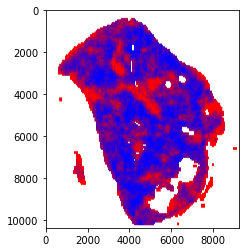

In [16]:
plt.imshow(hmap,vmin=0,vmax=1)

By the way, as an example, observe that to compute SAMPLER represenation of this WSI we run the following code.

In [17]:
wsi_SAMPLER_rep=SAMPLER.SAMPLERrep(feats,pers=[5,15,25,35,45,55,65,75,85,95])

In [27]:
del DS0  ###to save space

Now we do an ILC example using a slide in the test set.

In [29]:
slide='TCGA-B6-A0RQ-01Z-00-DX1.68B4F49D-9F81-4501-BC66-0349012077C8.svs'
W=pickle.load(open(slide+'.p','rb'))
feats=W['feats'] ##tile level inceptionv3 features
Tlocs=W['locs'] ##top left corner of the corresponding small tile

XR=feats[:,:fdim]  ###inceptionv3 feats of small tiles
XP=feats[:,fdim:2*fdim]  ###inceptionv3 feats of medium tiles
XB=feats[:,2*fdim:]  ###inceptionv3 feats of large tiles

locs=Tlocs/dsr
locs=locs.astype(dtype=np.int32)

DS1={}
DS1['R']=SAMPLER.Sscore(XR,XtabR,LtabR_C1,Wmat[:,:fdim],pers)  ###small tiles
DS1['P']=SAMPLER.Sscore(XP,XtabP,LtabP_C1,Wmat[:,fdim:2*fdim],pers) ###medium tiles
DS1['B']=SAMPLER.Sscore(XB,XtabB,LtabB_C1,Wmat[:,2*fdim:],pers)   ###large tiles

scores=np.abs(np.sum(DS1['R'],axis=1)+np.sum(DS1['P'],axis=1)+np.sum(DS1['B'],axis=1))

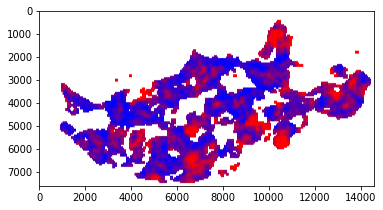

In [30]:
norm_scores=SAMPLER.normalize_scores(scores)
hmap=SAMPLER.hmapgen3(norm_scores,locs,int(512/dsr))
plt.imshow(hmap)